In [2]:
import ROOT as r
import matplotlib.pyplot as plt
import numpy as np
import pickle

Welcome to JupyROOT 6.30/02


## Load latest version of fits and cross sections

In [64]:
fFit = r.TFile.Open("/nashome/m/micarrig/icarus/gundam/gundam-icarus/configsNue/nue_asimov.root", "READ")
fXsec = r.TFile.Open("/nashome/m/micarrig/icarus/gundam/gundam-icarus/configsNue/nue_asimovXSec.root", "READ")

### Plot Covariance

Warning in <TCanvas::Constructor>: Deleting canvas with same name: c
Info in <TCanvas::Print>: png file /nashome/m/micarrig/icarus/gundam/gundam-icarus/configsNue/plots/covarianceMatrix.png has been created


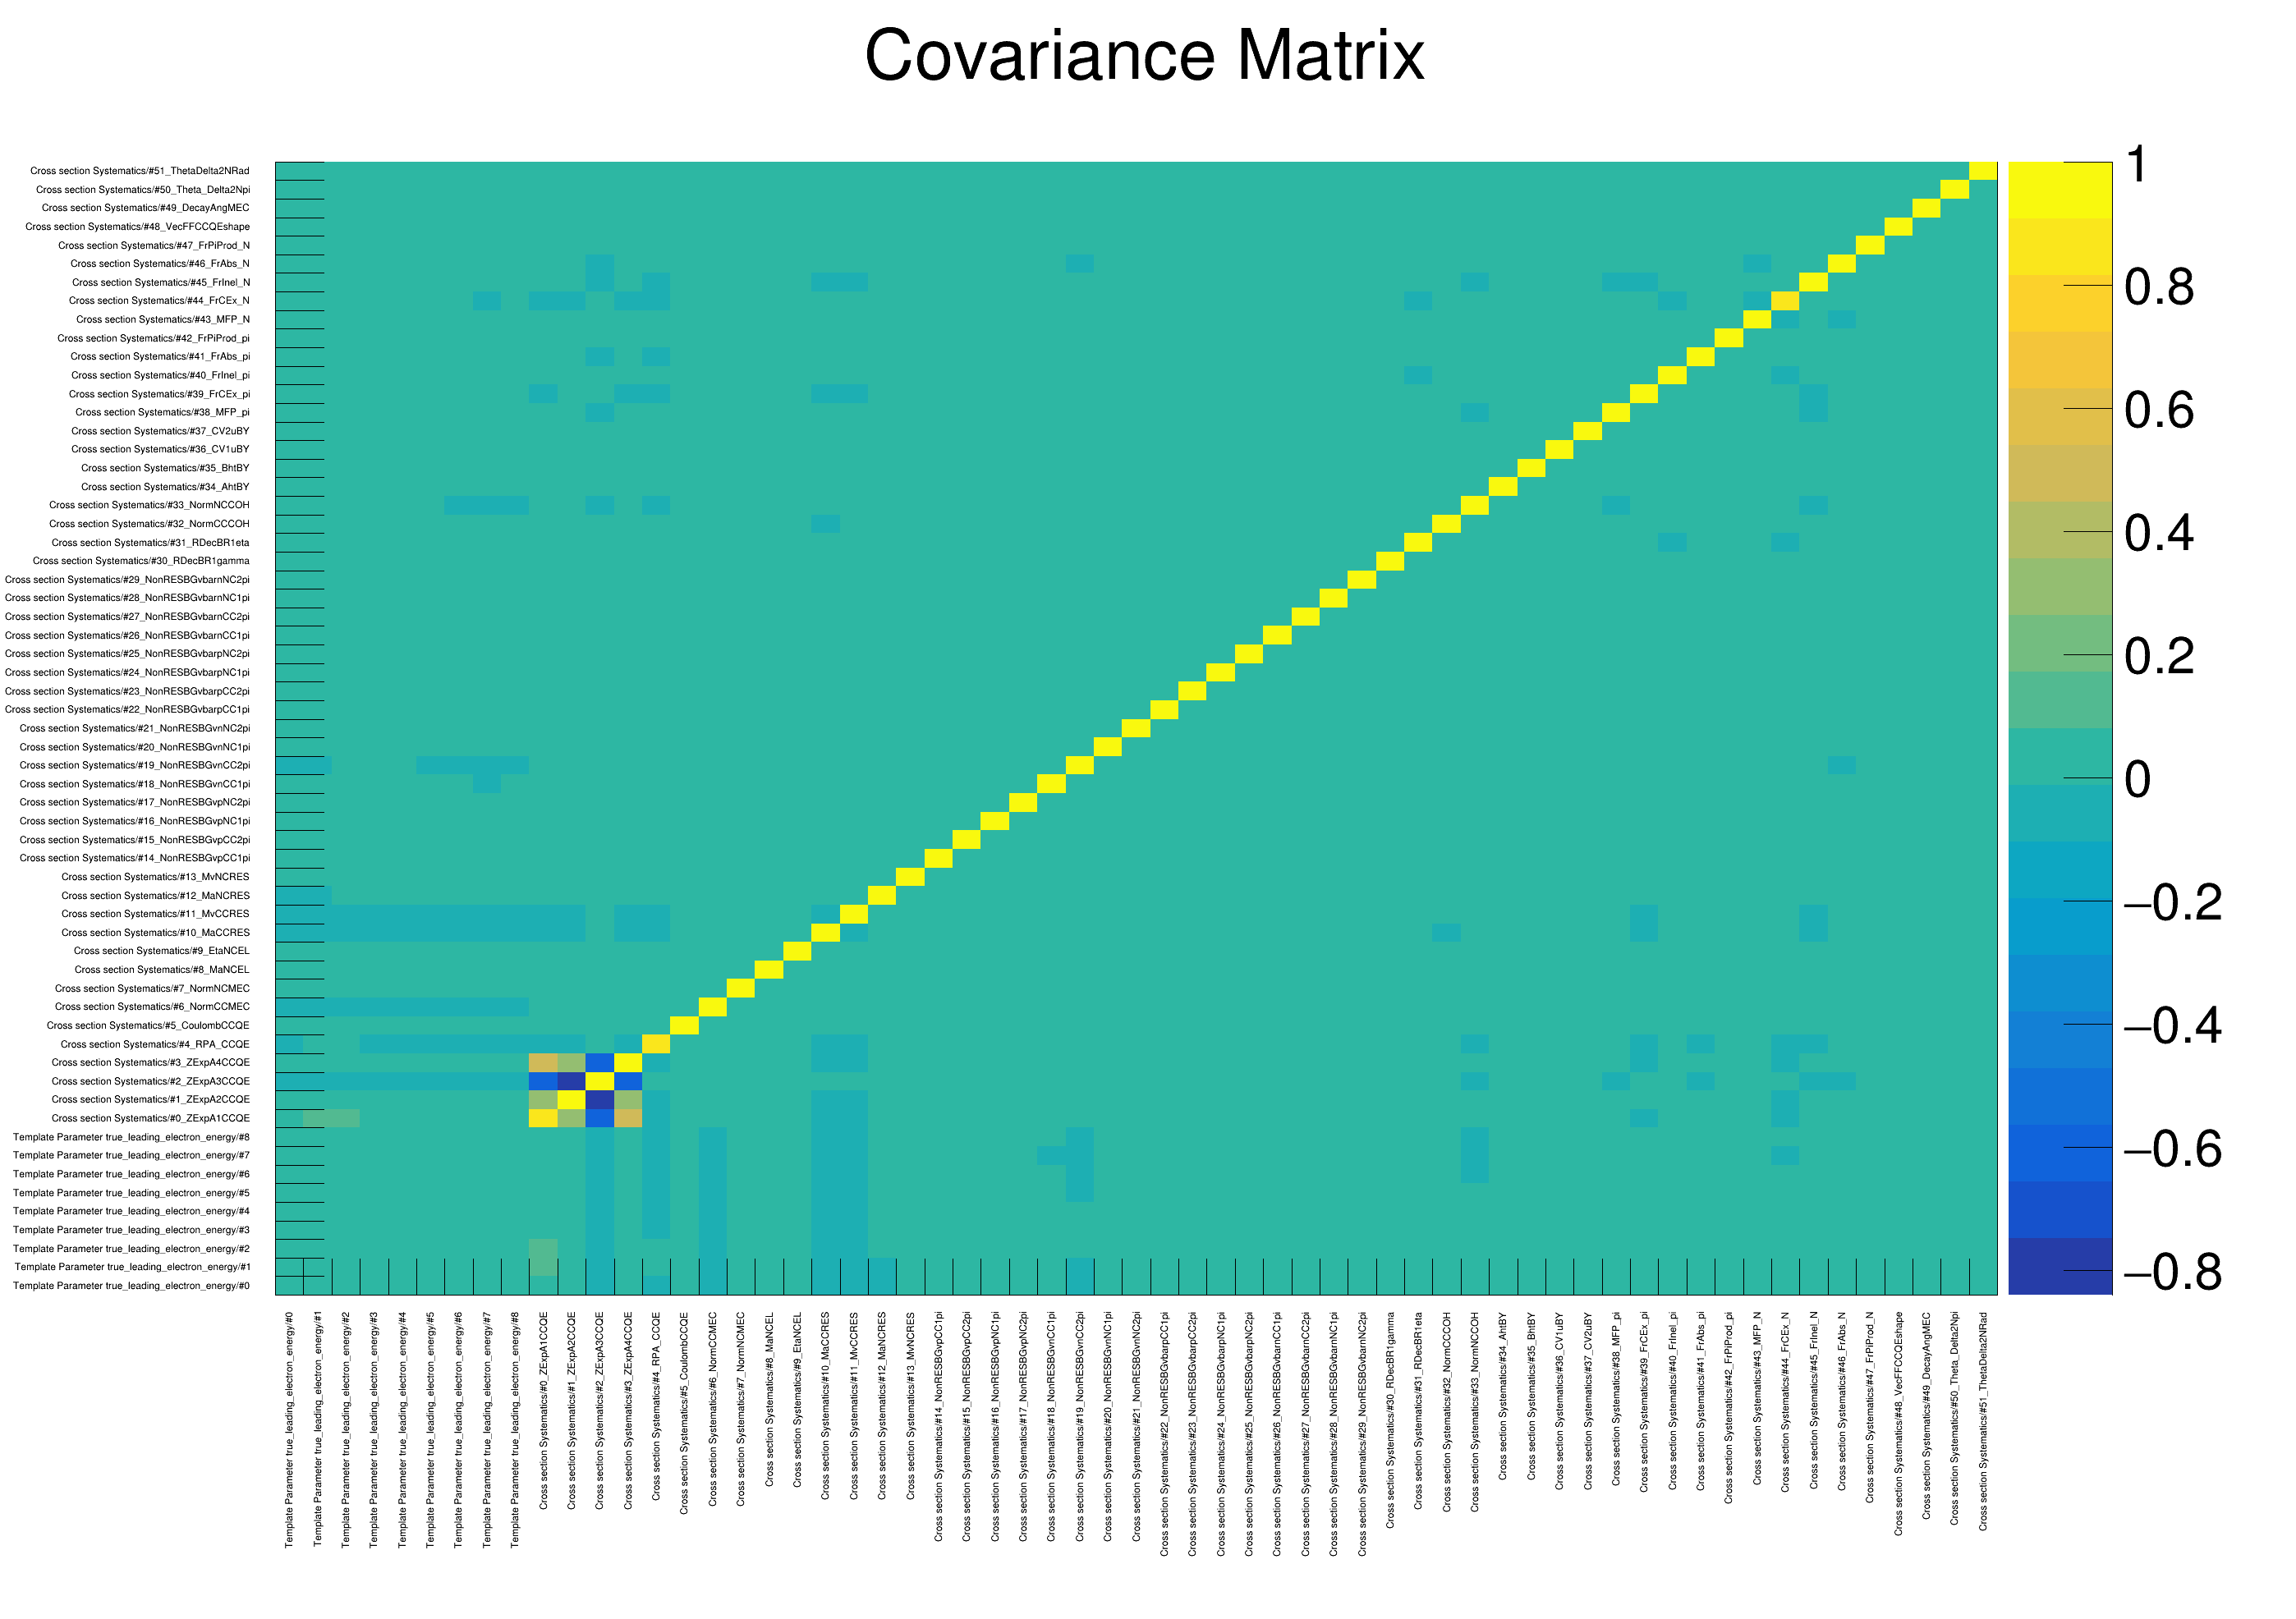

In [68]:
c = r.TCanvas("c", "c", 2800, 2000)
h_cov = fFit.Get("FitterEngine/postFit/Hesse/hessian/postfitCovariance_TH2D")

r.gStyle.SetPalette(r.kBird)

h_cov.SetTitle("Covariance Matrix;;")
# h_cov.GetZaxis().SetRangeUser(-10, 10)
h_cov.GetXaxis().SetLabelSize(0.01)
h_cov.GetYaxis().SetLabelSize(0.01)
h_cov.Draw("COLZ")
# c.SetLogz()
c.SetLeftMargin(0.12)
c.SetBottomMargin(0.2)
c.SetRightMargin(0.13)
c.Draw()
c.SaveAs("/nashome/m/micarrig/icarus/gundam/gundam-icarus/configsNue/plots/covarianceMatrix.png")


### Plot Correlation

Warning in <TCanvas::Constructor>: Deleting canvas with same name: c
Info in <TCanvas::Print>: png file /nashome/m/micarrig/icarus/gundam/gundam-icarus/configsNue/plots/correlationMatrix.png has been created


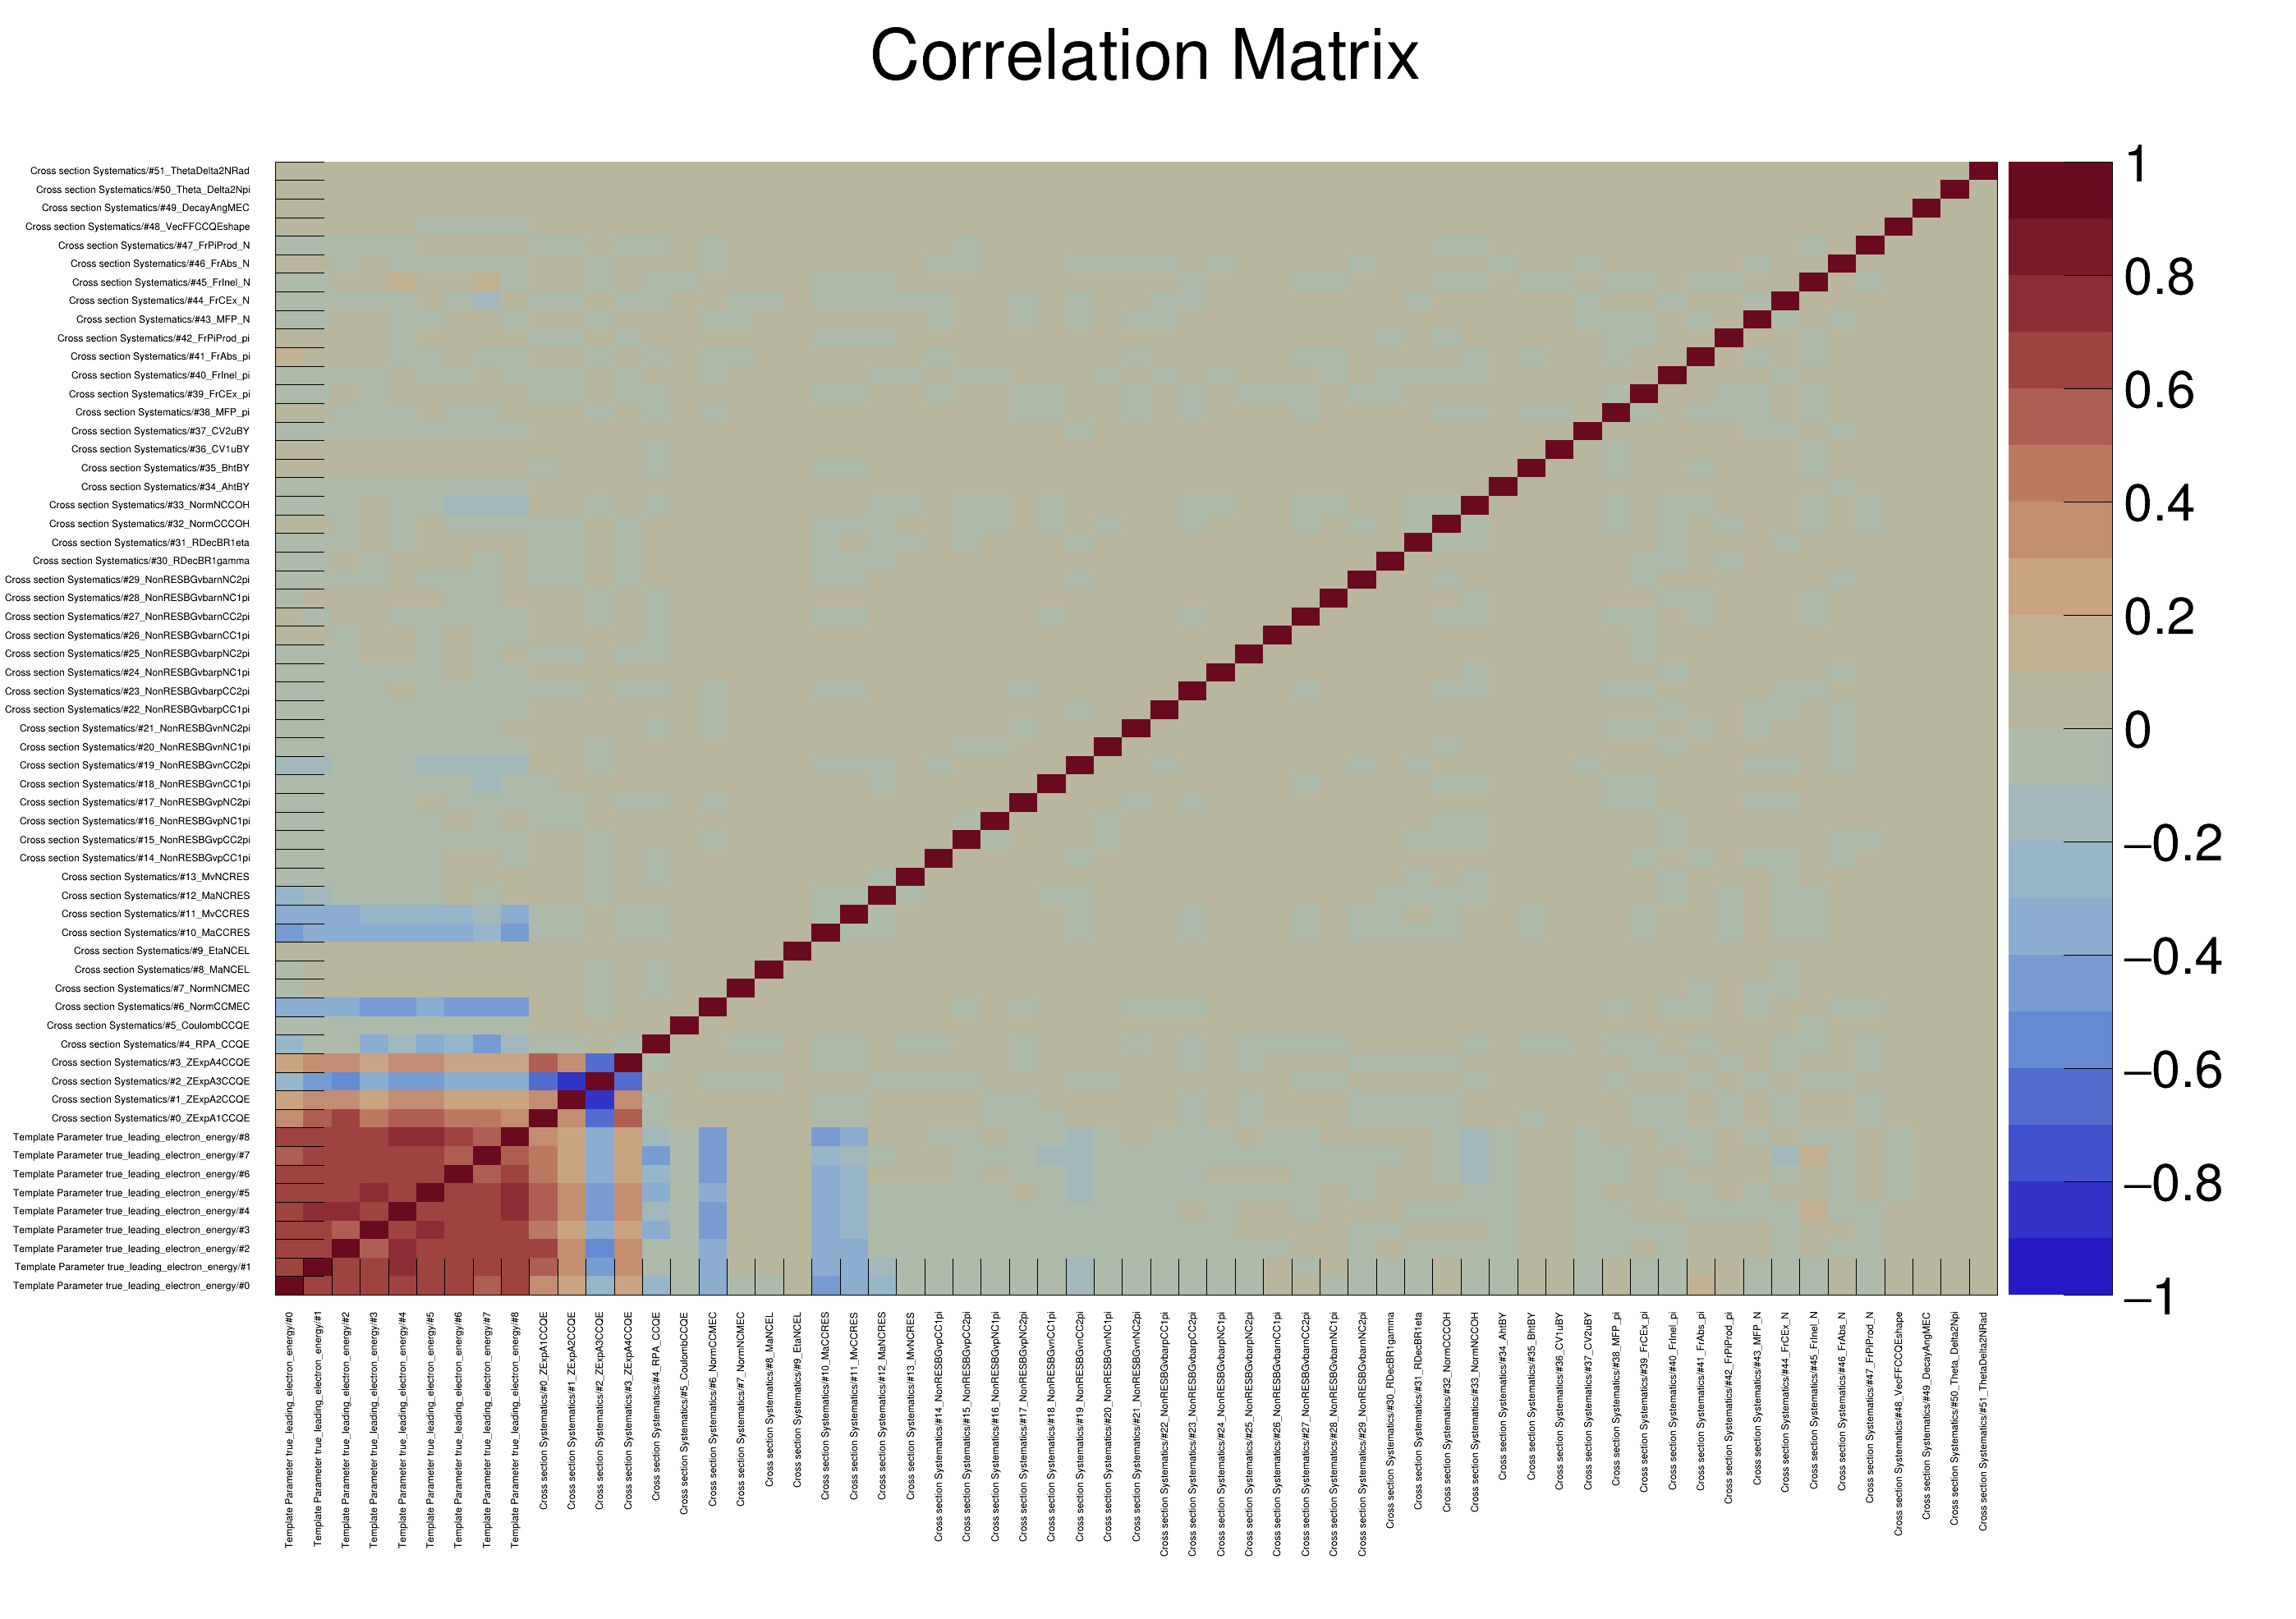

In [166]:
c = r.TCanvas("c", "c", 2800, 2000)
h_cor = fFit.Get("FitterEngine/postFit/Hesse/hessian/postfitCorrelation_TH2D")

r.gStyle.SetPalette(r.kThermometer)

h_cor.SetTitle("Correlation Matrix;;")
h_cor.GetZaxis().SetRangeUser(-1, 1)
h_cor.GetXaxis().SetLabelSize(0.01)
h_cor.GetYaxis().SetLabelSize(0.01)
h_cor.GetXaxis().LabelsOption("v")
h_cor.Draw("COLZ")
# c.SetLogz()
c.SetLeftMargin(0.12)
c.SetBottomMargin(0.2)
c.SetRightMargin(0.13)
c.SaveAs("/nashome/m/micarrig/icarus/gundam/gundam-icarus/configsNue/plots/correlationMatrix.png")
c.Draw()


### Plot pre/post fits

Warning in <TCanvas::Constructor>: Deleting canvas with same name: c
Info in <TCanvas::Print>: png file /nashome/m/micarrig/icarus/gundam/gundam-icarus/configsNue/plots/TemplateParameters.png has been created


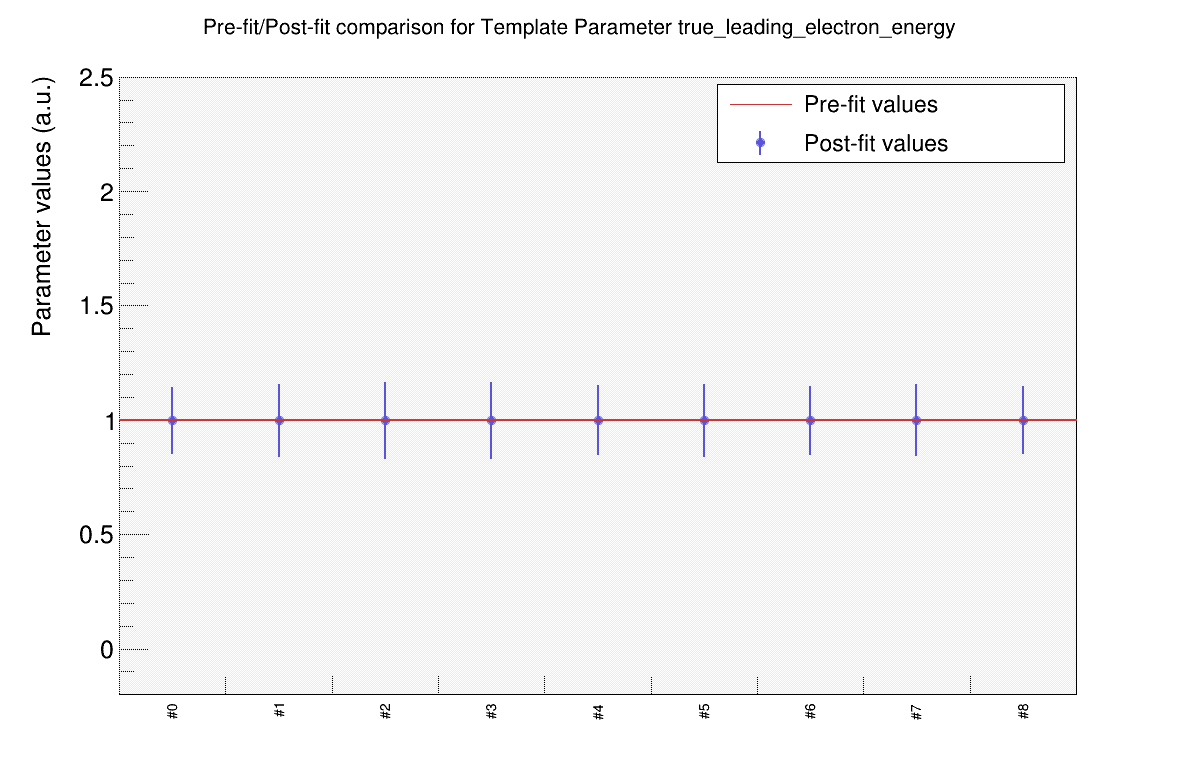

In [4]:
# this plot is drawn in the wrong order for some reason and so it needs to be completely redrawn by hand

c_par = fFit.Get("FitterEngine/postFit/Hesse/errors/Template Parameter true_leading_electron_energy/values/fitConstraints_TCanvas")

primitives = list(c_par.GetListOfPrimitives())  # make a Python list copy

# Identify your objects by name or type
h_prefit = c_par.GetPrimitive("preFitErrors")
h_postfit = c_par.GetPrimitive("postFitErrors")
h_line = c_par.GetPrimitive("preFitErrorHistLine")
tpave = c_par.GetPrimitive("TPave")  # or get by index/type

# Clone all objects BEFORE drawing
objects_to_draw = []

if h_prefit:
    objects_to_draw.append(h_prefit.Clone())
if h_postfit:
    objects_to_draw.append(h_postfit.Clone())
if h_line:
    objects_to_draw.append(h_line.Clone())
if tpave:
    objects_to_draw.append(tpave.Clone())

for i in range(2, 11):
    objects_to_draw.append(primitives[i].Clone())

# Now create a new canvas
c = r.TCanvas("c", "c", 1200, 800)

h_prefit.Draw()

# Draw the objects in the correct order
for i, obj in enumerate(objects_to_draw[::-1]):
    obj.Draw("same")


c.Modified()
c.Draw()
c.SaveAs("/nashome/m/micarrig/icarus/gundam/gundam-icarus/configsNue/plots/TemplateParameters.png")

Info in <TCanvas::Print>: png file /nashome/m/micarrig/icarus/gundam/gundam-icarus/configsNue/plots/CrossSectionSystematics.png has been created


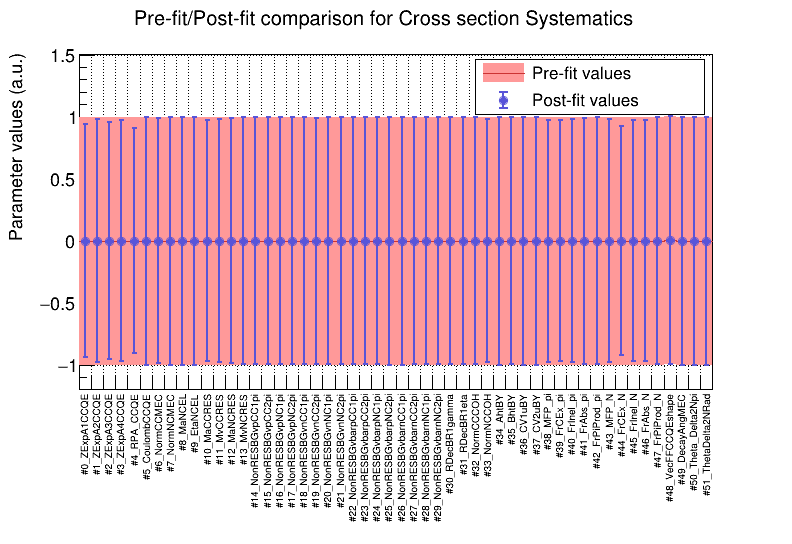

In [ ]:
c_par = fFit.Get("FitterEngine/postFit/Hesse/errors/Cross section Systematics/values/fitConstraints_TCanvas")

                "data_pre = np.array(h_mc_pre)",
                "data_post = np.array(h_mc_post)",
                "",
                "n_bins = len(x_vals)",
                "",
                "labels = [r\"$\\nu_e$ Signal\", r\"$\\nu_e$ OOFV\", r\"$\\nu_\\mu$\", r\"$\\nu$ OOFV\", r\"$\\nu$ NC\"]",
                "category_colors = ['#011959', '#1C5A62', '#687B3E', '#D29343', '#FDB7BC']",
                "",
                "def draw_stacked_with_band(ax, stack_data, errors, title, data_y=None, data_yerr=None):",
                "    # Draw stacked components (stack_data shape: n_categories x n_bins).",
                "    bottom = np.zeros(n_bins)",
                "    totals_per_cat = stack_data.sum(axis=1)",
                "    order = np.argsort(totals_per_cat)  # draw from smallest to largest total contribution",
                "",
                "    for i in order:",
                "        ax.bar(",
                "            x_vals,",
                "            stack_data[i],",
                "            bottom=bottom,",
                "            width=widths,",
                "            label=labels[i],",
                "            color=category_colors[i],",
                "            align='center'",
                "        )",
                "        bottom += stack_data[i]",
                "",
                "    # Build edges and total prediction per bin",
                "    x_edges = [x_vals[0] - widths[0] / 2.0]",
                "    x_edges.extend([x + w / 2.0 for x, w in zip(x_vals, widths)])",
                "    total_pred = np.sum(stack_data, axis=0)",
                "    err = np.asarray(errors, dtype=float)",
                "    lower = np.maximum(0.0, total_pred - err)",
                "    upper = total_pred + err",
                "    ax.fill_between(",
                "        x_edges,",
                "        np.r_[lower, lower[-1]],",
                "        np.r_[upper, upper[-1]],",
                "        step='post',",
                "        facecolor='0.8',",
                "        edgecolor='gray',",
                "        hatch='///',",
                "        alpha=0.5,",
                "        label='Uncertainty'",
                "    )",
                "",
                "    # Overlay data points and statistical uncertainties.",
                "    if data_y is not None:",
                "        y = np.asarray(data_y, dtype=float)",
                "        yerr = np.asarray(data_yerr, dtype=float) if data_yerr is not None else np.zeros_like(y)",
                "        ax.errorbar(",
                "            x_vals,",
                "            y,",
                "            yerr=yerr,",
                "            fmt='o',",
                "            color='black',",
                "            ecolor='black',",
                "            elinewidth=1.5,",
                "            capsize=0,",
                "            markersize=4,",
                "            label='Data',",
                "            zorder=10",
                "        )",
                "",
                "    ax.set_ylabel(\"Counts\")",
                "    ax.set_title(title)",
                "    return x_edges, total_pred, err",
                "",
                "def draw_ratio(ax, total_pred, err, data_y, data_yerr, x_edges, title=None, center=1.0, pad=(0.5,1.5)):",
                "    # Compute ratio and plot band = (total +/- err) / total",
                "    tot = np.asarray(total_pred, dtype=float)",
                "    data_y = np.asarray(data_y, dtype=float)",
                "    data_yerr = np.asarray(data_yerr, dtype=float)",
                "",
                "    # avoid divide-by-zero: where tot==0 set to nan so ratios plot as nan",
                "    denom = tot.copy()",
                "    denom[denom == 0.0] = np.nan",
                "",
                "    ratio = data_y / denom",
                "    ratio_err = data_yerr / denom",
                "",
                "    lower = np.maximum(0.0, (tot - err) / denom)",
                "    upper = (tot + err) / denom",
                "",
                "    ax.fill_between(",
                "        x_edges,",
                "        np.r_[lower, lower[-1]],",
                "        np.r_[upper, upper[-1]],",
                "        step='post',",
                "        facecolor='0.8',",
                "        edgecolor='none',",
                "        alpha=0.6,",
                "        zorder=1,",
                "    )",
                "    ax.errorbar(x_vals, ratio, yerr=ratio_err, fmt='o', color='black', zorder=10)",
                "    ax.axhline(center, color='gray', linestyle='--', linewidth=1)",
                "    ax.set_ylim(pad)",
                "    ax.set_xlabel(\"Reco Leading Electron Energy [MeV]\")",
                "    if title is not None:",
                "        ax.set_title(title)",
                "    ax.set_ylabel(\"Data / Pred\")",
                "",
                "# Create a 2x2 layout: top row = main plots, bottom row = ratio plots",
                "fig, axes = plt.subplots(2, 2, figsize=(16, 8), gridspec_kw={'height_ratios': [3, 1]}, sharex='col')",
                "ax1_main, ax2_main = axes[0, 0], axes[0, 1]",
                "ax1_ratio, ax2_ratio = axes[1, 0], axes[1, 1]",
                "",
                "edges1, tot1, err1 = draw_stacked_with_band(ax1_main, data_pre, preFitErrors, \"Pre-fit\", data, data_err)",
                "edges2, tot2, err2 = draw_stacked_with_band(ax2_main, data_post, postFitErrors, \"Post-fit\", data, data_err)",
                "",
                "# Draw ratio panels under each main plot",
                "draw_ratio(ax1_ratio, tot1, err1, data, data_err, edges1)",
                "draw_ratio(ax2_ratio, tot2, err2, data, data_err, edges2)",
                "",
                "# Legends on main axes",
                "ax1_main.legend(loc='upper right')",
                "ax2_main.legend(loc='upper right')",
                "",
                "plt.tight_layout()",
                "plt.show()"
### Extra plots of variables

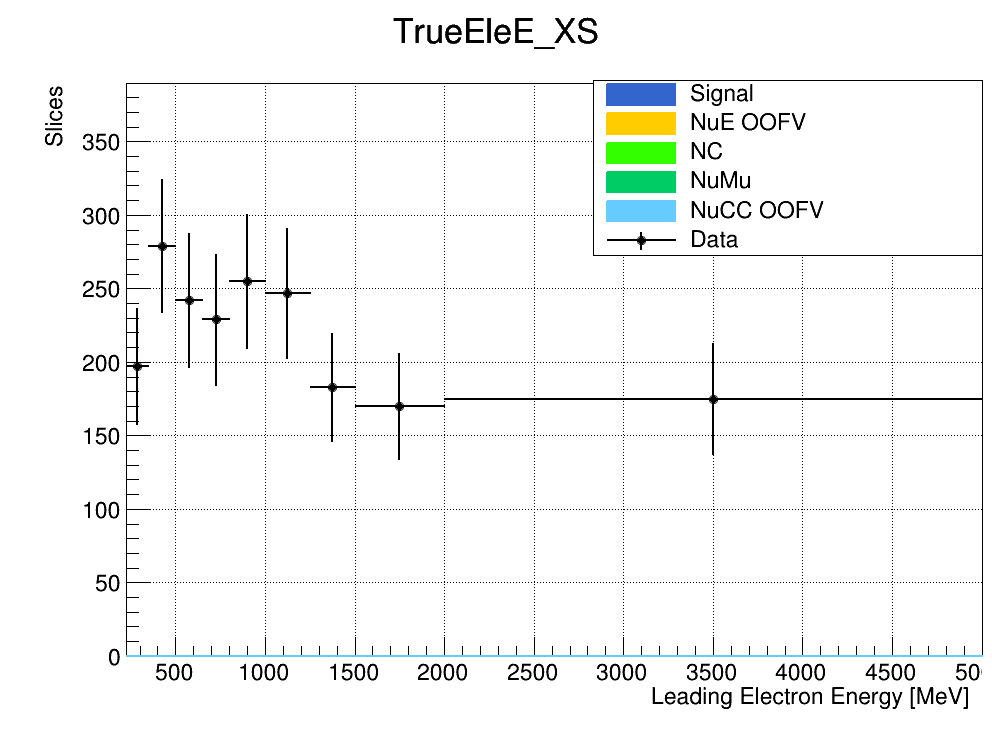

In [40]:
c_recoEleE = fXsec.Get("calcXsec/plots/canvas/true_leading_electron_energy/category/samples_n0_TCanvas")

c_recoEleE.Draw()

## Draw pre/post fit error bars

In [111]:
fPreError = r.TFile.Open("/nashome/m/micarrig/icarus/gundam/gundam-icarus/configsNue/nue_asimov_prefit.root", "READ")
fPostError = r.TFile.Open("/nashome/m/micarrig/icarus/gundam/gundam-icarus/configsNue/nue_asimov_postfit.root", "READ")

scaleFactor = 10.6

In [112]:
h_prefit = fPreError.Get("toyGen/histograms/signal_EleE_pre_fit_TH1D")
h_postfit = fPostError.Get("toyGen/histograms/signal_EleE_TH1D")

print(type(h_prefit), type(h_postfit))

# prefitName = None
# postfitName = None
# for x in c_prefit_error.GetListOfPrimitives():
#     if "Data_slot0" in x.GetName():
#         prefitName = x.GetName()
#         break

# for x in c_postfit_error.GetListOfPrimitives():
#     if "Data_slot0" in x.GetName():
#         postfitName = x.GetName()
#         break

# h_prefit = c_prefit_error.GetPrimitive(prefitName)
# h_postfit = c_postfit_error.GetPrimitive(postfitName)

postFitErrors = []
preFitErrors = []
data = []
for i in range(1, h_prefit.GetNbinsX() + 1):
    bounds = [float(x) for x in h_prefit.GetXaxis().GetBinLabel(i).split(':')[-1].strip().replace("[", "").replace("]", "").split(',')]
    width = bounds[1] - bounds[0]
    preFitErrors.append(h_prefit.GetBinError(i) * width)
    postFitErrors.append(h_postfit.GetBinError(i) * width)
    data.append(h_prefit.GetBinContent(i) * width)
    print("bin bounds:", bounds, "bin width:", width)

# preFitErrors.insert(0, 0.0)
# postFitErrors.insert(0, 0.0)

# preFitErrors = [x for x in preFitErrors]
# postFitErrors = [x  for x in postFitErrors]

print("Pre-fit errors:", preFitErrors)
print("Post-fit errors:", postFitErrors)


<class cppyy.gbl.TH1D at 0xf0c18a0> <class cppyy.gbl.TH1D at 0xf0c18a0>
bin bounds: [225.0, 350.0] bin width: 125.0
bin bounds: [350.0, 500.0] bin width: 150.0
bin bounds: [500.0, 650.0] bin width: 150.0
bin bounds: [650.0, 800.0] bin width: 150.0
bin bounds: [800.0, 1000.0] bin width: 200.0
bin bounds: [1000.0, 1250.0] bin width: 250.0
bin bounds: [1250.0, 1500.0] bin width: 250.0
bin bounds: [1500.0, 2000.0] bin width: 500.0
bin bounds: [2000.0, 5000.0] bin width: 3000.0
Pre-fit errors: [245.7418191291923, 90.84042109909541, 74.8778581265726, 64.0289764154577, 69.05244358768661, 59.47716501633817, 41.32532951411354, 43.59068812763409, 39.87940127219006]
Post-fit errors: [156.7142538223598, 43.015524235218116, 37.24792356639835, 33.32959708345017, 38.85782099916196, 32.25508067871893, 26.370820762998967, 27.06293606455102, 25.91684894763857]


Found 54 rectangles
Rectangle 0: x=225.0, y=0.0, width=125.0, height=1.8457059929880053
[[225.           0.        ]
 [350.           0.        ]
 [350.           1.84570599]
 [225.           1.84570599]
 [225.           0.        ]]
Rectangle 1: x=350.0, y=0.0, width=150.0, height=1.1179995292397473
[[350.           0.        ]
 [500.           0.        ]
 [500.           1.11799953]
 [350.           1.11799953]
 [350.           0.        ]]
Rectangle 2: x=500.0, y=0.0, width=150.0, height=0.5722196814285541
[[5.00000000e+02 0.00000000e+00]
 [6.50000000e+02 0.00000000e+00]
 [6.50000000e+02 5.72219681e-01]
 [5.00000000e+02 5.72219681e-01]
 [5.00000000e+02 0.00000000e+00]]
Rectangle 3: x=650.0, y=0.0, width=150.0, height=0.663182989397086
[[6.50000000e+02 0.00000000e+00]
 [8.00000000e+02 0.00000000e+00]
 [8.00000000e+02 6.63182989e-01]
 [6.50000000e+02 6.63182989e-01]
 [6.50000000e+02 0.00000000e+00]]
Rectangle 4: x=800.0, y=0.0, width=200.0, height=0.2513820991218729
[[8.00000000e+02 

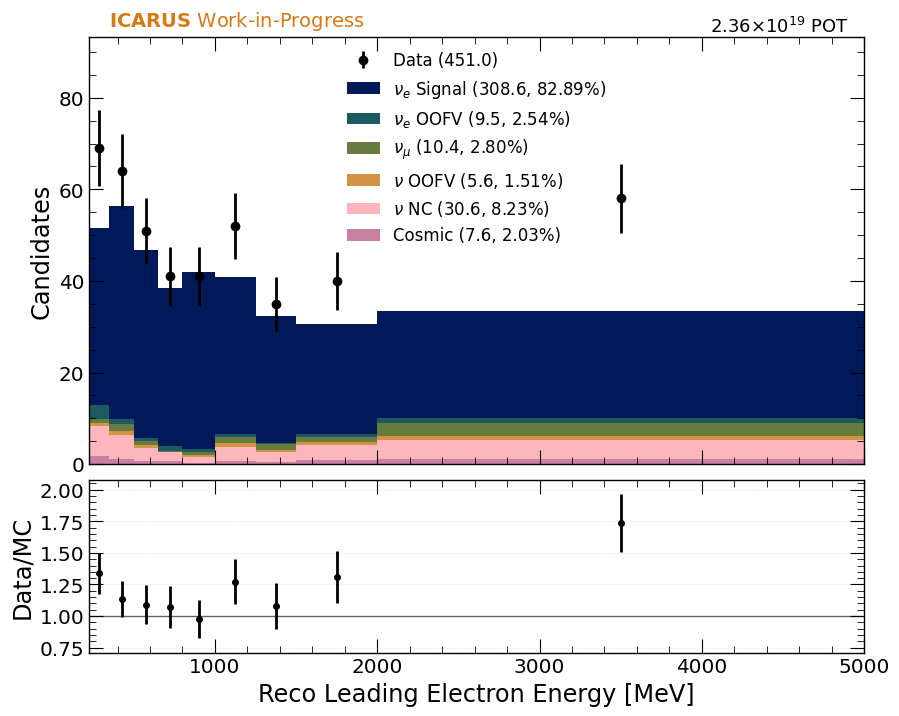

In [113]:
from matplotlib.container import ErrorbarContainer
from matplotlib.collections import LineCollection
from matplotlib.collections import PatchCollection
with open('/nashome/m/micarrig/icarus/nuESpine/plots/debug2/plot_reco_leading_electron_energy.pkl', 'rb') as f:
    eff_nuE = pickle.load(f)
eff_nuE.set_size_inches(10, 8)

axes = eff_nuE.get_axes()

ax = axes[0]

# Try PatchCollection first
patch_cols = [c for c in ax.get_children() if isinstance(c, PatchCollection)]
if patch_cols:
    patches = patch_cols[0].get_paths()
    for i, path in enumerate(patches[:5]):
        print(f"PatchCollection patch {i}:")
        print(path.vertices)
else:
    # Fallback: many saved plots store bars/bands as Rectangle artists
    rects = [p for p in ax.patches if p is not ax.patch]  # skip axes background
    print(f"Found {len(rects)} rectangles")

    for i, rect in enumerate(rects[:10]):
        x, y = rect.get_x(), rect.get_y()
        w, h = rect.get_width(), rect.get_height()
        verts = np.array([
            [x, y],
            [x + w, y],
            [x + w, y + h],
            [x, y + h],
            [x, y],  # closed polygon
        ])
        print(f"Rectangle {i}: x={x}, y={y}, width={w}, height={h}")
        print(verts)

In [114]:
import numpy as np
from matplotlib.collections import PatchCollection, PolyCollection

def apply_band_errors_strict(ax, errors, patch_index=0, method="midline"):
    """Apply +/-errors to an existing matplotlib uncertainty band stored as a PatchCollection.

    This is STRICT about binning: len(errors) must match the number of band polygons (paths).
    If it doesn't match, it raises a ValueError and makes no changes.

    Parameters
    ----------
    ax : matplotlib.axes.Axes
    errors : sequence of float
        Per-bin halfwidths in y-units (i.e. +/- error). Must match band bins 1:1.
    patch_index : int
        Which PatchCollection on the axes to edit (usually 0).
    method : {"midline", "mean"}
        How to define the center curve. "midline" preserves the original band center best.
    """
    patch_cols = [c for c in ax.get_children() if isinstance(c, PatchCollection)]
    rects = [p for p in ax.patches if p is not ax.patch]  # fallback: individual Rectangle artists
    if not patch_cols:
        # Some saved figures store only stacked bars and no separate top-band collection.
        return None
    pc = patch_cols[patch_index]
    paths = pc.get_paths()
    if not paths:
        raise RuntimeError("PatchCollection has no paths.")

    hw = np.asarray(errors, dtype=float)
    n_patches = len(paths)
    if len(hw) != n_patches:
        raise ValueError(
            "Error binning mismatch: "
            f"len(errors)={len(hw)} but band has {n_patches} bins/polygons. "
            "Refusing to apply errors. Provide one error per band bin."
        )

    for patch_i, path in enumerate(paths):
        V = path.vertices
        closed = (V.shape[0] > 2) and np.allclose(V[0], V[-1])
        Vwork = V[:-1].copy() if closed else V.copy()

        N = Vwork.shape[0]
        if N < 4:
            continue

        M = N // 2
        upper = Vwork[:M]
        lower = Vwork[M:]

        # sort by x to define a stable midline
        upper_s = upper[np.argsort(upper[:, 0])]
        lower_s = lower[np.argsort(lower[:, 0])]
        if lower_s.shape[0] != upper_s.shape[0]:
            ly = np.interp(upper_s[:, 0], lower_s[:, 0], lower_s[:, 1])
            lower_s = np.column_stack([upper_s[:, 0], ly])

        if method == "midline":
            center_y = 0.5 * (upper_s[:, 1] + lower_s[:, 1])
        else:
            center_y = np.full_like(upper_s[:, 1], np.mean(Vwork[:, 1]))

        hw_val = float(hw[patch_i])
        new_upper_y = center_y + hw_val
        new_lower_y = center_y - hw_val

        def replace_y(block, x_ref, y_new):
            # keep original x sampling; just update y with linear interp along x
            y_interp = np.interp(block[:, 0], x_ref, y_new)
            block[:, 1] = y_interp
            return block

        upper_new = replace_y(upper.copy(), upper_s[:, 0], new_upper_y)
        lower_new = replace_y(lower.copy(), lower_s[:, 0], new_lower_y)

        Vnew = np.vstack([upper_new, lower_new])
        if closed:
            Vnew = np.vstack([Vnew, Vnew[0]])
        path.vertices[:, :] = Vnew

    ax.figure.canvas.draw_idle()
    return pc

def apply_ratio_band_errors_strict(ax, rel_errors, band_index=0, center=1.0):
    """Rewrite the filled ratio band while leaving ratio points/error bars unchanged."""
    poly_cols = [c for c in ax.get_children() if isinstance(c, PolyCollection)]
    if not poly_cols:
        return None

    pc = poly_cols[band_index]
    paths = pc.get_paths()
    if not paths:
        raise RuntimeError("PolyCollection has no paths.")

    edges = np.unique(paths[0].vertices[:, 0])
    errors = np.asarray(rel_errors, dtype=float)
    n_bins = len(edges) - 1
    if len(errors) != n_bins:
        raise ValueError(
            "Error binning mismatch: "
            f"len(rel_errors)={len(errors)} but band has {n_bins} bins. "
            "Provide one relative error per ratio bin."
        )

    lower = np.r_[center - errors, center - errors[-1]]
    upper = np.r_[center + errors, center + errors[-1]]

    facecolors = pc.get_facecolors().copy()
    edgecolors = pc.get_edgecolors().copy()
    alpha = pc.get_alpha()
    zorder = pc.get_zorder()
    label = pc.get_label()

    pc.remove()
    new_pc = ax.fill_between(edges, lower, upper, step="post")
    if len(facecolors):
        new_pc.set_facecolor(facecolors)
    if len(edgecolors):
        new_pc.set_edgecolor(edgecolors)
    if alpha is not None:
        new_pc.set_alpha(alpha)
    new_pc.set_zorder(zorder)
    new_pc.set_label(label)
    ax.figure.canvas.draw_idle()
    return new_pc

In [115]:
def scale_stacked_histograms(ax, scale):
    """Scale stacked bar components on an Axes by a constant factor."""
    if scale <= 0:
        raise ValueError("scale must be > 0")

    bar_rectangles = [
        patch for patch in ax.patches
        if patch is not ax.patch and hasattr(patch, "get_width") and patch.get_width() > 0
    ]
    if not bar_rectangles:
        raise RuntimeError("No stacked bar rectangles found on this Axes.")

    for rect in bar_rectangles:
        rect.set_y(rect.get_y() * scale)
        rect.set_height(rect.get_height() * scale)

    ax.relim()
    ax.autoscale_view()
    ax.figure.canvas.draw_idle()
    return bar_rectangles

In [116]:
def _stack_bin_geometry(ax):
    """Return (edges, stack_totals) inferred from stacked bar rectangles on an axis."""
    bars = [
        patch for patch in ax.patches
        if patch is not ax.patch and hasattr(patch, "get_width") and patch.get_width() > 0
    ]
    if not bars:
        raise RuntimeError("No stacked bar rectangles found on this Axes.")

    # Group by bin x/width and keep the stacked top (max y + height) per bin.
    grouped = {}
    for rect in bars:
        x = float(rect.get_x())
        w = float(rect.get_width())
        key = (round(x, 10), round(w, 10))
        grouped.setdefault(key, []).append(rect)

    bins = []
    for (x, w), rects in grouped.items():
        top = max(float(r.get_y() + r.get_height()) for r in rects)
        bins.append((x, w, top))

    bins.sort(key=lambda item: item[0])
    edges = [bins[0][0]] + [x + w for x, w, _ in bins]
    totals = np.array([top for _, _, top in bins], dtype=float)
    return np.array(edges, dtype=float), totals


def compute_scaled_main_ylim(ax, scaled_errors=None, pad_frac=0.12, min_ymax=1.0, include_errors=False):
    """Compute y-max from scaled stack, optionally including scaled error envelope."""
    _, totals = _stack_bin_geometry(ax)
    y_top = float(np.max(totals)) if len(totals) else 0.0

    if include_errors and scaled_errors is not None:
        err = np.asarray(scaled_errors, dtype=float)
        if len(err) == len(totals):
            y_top = float(np.max(totals + err))

    ymax = max(min_ymax, y_top * (1.0 + pad_frac))
    return ymax


def ensure_top_error_band(ax, errors):
    """Update existing top uncertainty band if present, otherwise draw one from stack totals."""
    updated = apply_band_errors_strict(ax, errors)
    if updated is not None:
        return updated

    edges, totals = _stack_bin_geometry(ax)
    err = np.asarray(errors, dtype=float)
    if len(err) != len(totals):
        raise ValueError(
            f"Top-band binning mismatch: len(errors)={len(err)} but stacked bins={len(totals)}"
        )

    lower = np.maximum(0.0, totals - err)
    upper = totals + err
    band = ax.fill_between(
        edges,
        np.r_[lower, lower[-1]],
        np.r_[upper, upper[-1]],
        step="post",
        facecolor="0.75",
        edgecolor="black",
        hatch="///",
        linewidth=0.0,
        alpha=0.5,
        zorder=6,
        label="Total Uncertainty",
    )
    ax.figure.canvas.draw_idle()
    return band


def ensure_ratio_error_band(ax, rel_errors, edges):
    """Update existing ratio band if present, otherwise draw a new MC-uncertainty band."""
    updated = apply_ratio_band_errors_strict(ax, rel_errors)
    if updated is not None:
        return updated

    err = np.asarray(rel_errors, dtype=float)
    edges = np.asarray(edges, dtype=float)
    n_bins = len(edges) - 1
    if len(err) != n_bins:
        raise ValueError(
            f"Ratio-band binning mismatch: len(rel_errors)={len(err)} but stacked bins={n_bins}"
        )

    lower = 1.0 - err
    upper = 1.0 + err
    band = ax.fill_between(
        edges,
        np.r_[lower, lower[-1]],
        np.r_[upper, upper[-1]],
        step="post",
        facecolor="0.75",
        edgecolor="none",
        alpha=0.5,
        zorder=0,
        label="MC Uncertainty",
    )
    ax.figure.canvas.draw_idle()
    return band

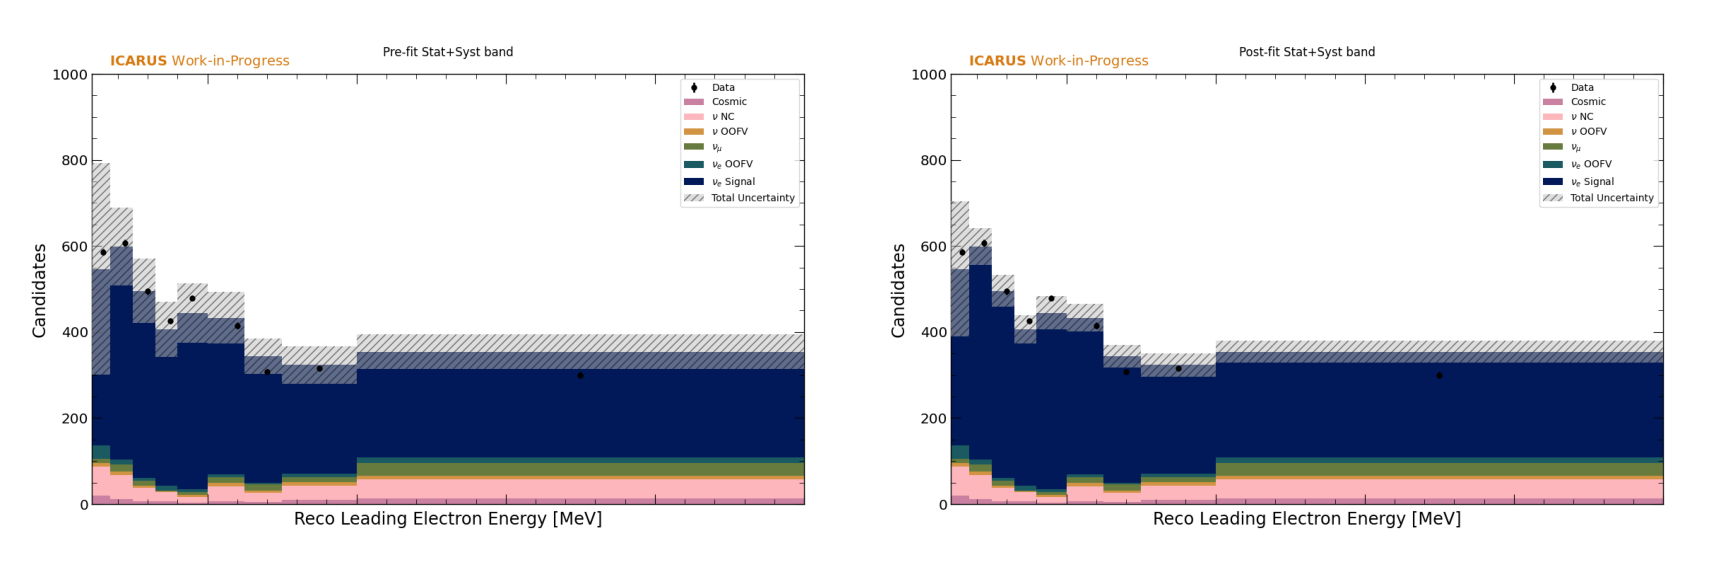

In [117]:
import pickle
import re
import matplotlib.pyplot as plt
from matplotlib.container import ErrorbarContainer
from IPython.display import display

def load_eff_nuE(path='/nashome/m/micarrig/icarus/nuESpine/plots/debug2/plot_reco_leading_electron_energy.pkl'):
    with open(path, 'rb') as f:
        fig = pickle.load(f)
    fig.set_size_inches(12, 8)
    return fig

def fig_to_rgb(fig):
    """Rasterize a Matplotlib figure to an RGB uint8 array (uses buffer_rgba; no deprecation warning)."""
    fig.canvas.draw()
    buf = np.asarray(fig.canvas.buffer_rgba())  # (H,W,4) uint8
    return buf[..., :3].copy()

def hide_existing_data_errorbars(ax):
    """Hide existing data points/errorbars so custom points can be overlaid cleanly."""
    for container in list(ax.containers):
        if isinstance(container, ErrorbarContainer):
            line = container.lines[0]
            if line is not None:
                line.set_visible(False)
                line.set_label("_nolegend_")
            for capline in container.lines[1]:
                capline.set_visible(False)
            for barlinecol in container.lines[2]:
                barlinecol.set_visible(False)

def extract_first_errorbar_points(ax):
    """Extract x, y, yerr from the first visible ErrorbarContainer."""
    for container in ax.containers:
        if isinstance(container, ErrorbarContainer):
            line = container.lines[0]
            if line is None:
                continue
            x = np.asarray(line.get_xdata(), dtype=float)
            y = np.asarray(line.get_ydata(), dtype=float)
            yerr = np.zeros_like(y)
            barcols = container.lines[2]
            if barcols:
                segs = barcols[0].get_segments()
                if len(segs) == len(y):
                    for i, seg in enumerate(segs):
                        yerr[i] = abs(seg[1][1] - seg[0][1]) / 2.0
            return x, y, yerr
    raise RuntimeError("No ErrorbarContainer found on this axis to extract points.")

def strip_counts_and_percentages(label):
    return re.sub(r"\s*\([^)]*\)", "", label).strip()

def clean_legend_labels(ax):
    handles, labels = ax.get_legend_handles_labels()
    def is_handle_visible(h):
        if isinstance(h, ErrorbarContainer):
            line = h.lines[0]
            return (line is not None) and line.get_visible()
        return hasattr(h, "get_visible") and h.get_visible()

    # Prefer visible handles and keep Data first in the legend.
    chosen = {}
    for h, lbl in zip(handles, labels):
        lbl2 = strip_counts_and_percentages(lbl)
        if not lbl2 or lbl2 == "_nolegend_":
            continue
        if lbl2 not in chosen:
            chosen[lbl2] = h
        elif (not is_handle_visible(chosen[lbl2])) and is_handle_visible(h):
            chosen[lbl2] = h

    out_labels = []
    if "Data" in chosen:
        out_labels.append("Data")
    out_labels.extend([lbl for lbl in chosen.keys() if lbl != "Data"])
    out_handles = [chosen[lbl] for lbl in out_labels]
    if out_handles:
        ax.legend(out_handles, out_labels, loc="upper right")

def remove_pot_text(ax):
    for txt in list(ax.texts):
        if "POT" in txt.get_text():
            txt.remove()

def remove_ratio_axis(fig):
    axes = fig.get_axes()
    if len(axes) < 2:
        return axes[0]
    ax_top = axes[0]
    for extra in axes[1:]:
        extra.remove()
    # Expand former top panel to fill figure space.
    ax_top.set_position([0.10, 0.12, 0.84, 0.76])
    ax_top.set_xlabel("Reco Leading Electron Energy [MeV]")
    return ax_top

def apply_custom_points(ax, custom_points=None):
    """Replace existing data points. If custom_points is None, use extracted defaults."""
    x_default, y_default, yerr_default = extract_first_errorbar_points(ax)

    if custom_points is None:
        x_new, y_new, yerr_new = x_default, y_default, yerr_default
    else:
        x_new = np.asarray(custom_points["x"], dtype=float)
        y_new = np.asarray(custom_points["y"], dtype=float)
        yerr_new = np.asarray(custom_points["yerr"], dtype=float)

    hide_existing_data_errorbars(ax)
    ax.errorbar(
        x_new,
        y_new,
        yerr=yerr_new,
        fmt="o",
        color="black",
        ecolor="black",
        elinewidth=2,
        capsize=0,
        markersize=5,
        label="Data",
        zorder=10,
    )

# Load two independent copies of the figure
fig_pre = load_eff_nuE()
fig_post = load_eff_nuE()

ax_pre = fig_pre.get_axes()[0]
ax_post = fig_post.get_axes()[0]

# Scale all stacked histogram components by a constant factor
stackScaleFactor = globals().get('scaleFactor', 1.0)
scale_stacked_histograms(ax_pre, stackScaleFactor)
scale_stacked_histograms(ax_post, stackScaleFactor)

# Use errors exactly as provided by preFitErrors/postFitErrors.
ensure_top_error_band(ax_pre, preFitErrors)
ensure_top_error_band(ax_post, postFitErrors)

# Set a shared y-limit from scaled stack heights.
# shared_ymax = max(
#     compute_scaled_main_ylim(ax_pre, preFitErrors, include_errors=False),
#     compute_scaled_main_ylim(ax_post, postFitErrors, include_errors=False),
# )

shared_ymax = 1000

ax_pre.set_ylim(0.0, shared_ymax)
ax_post.set_ylim(0.0, shared_ymax)

# Define your custom data points here (edit these arrays).
new_data_pre = {
    "x": [300, 450, 600, 750, 900, 1200, 1400, 1750, 3500],
    "y": data,
    "yerr": [8, 8, 7, 6, 6, 7, 6, 6, 8],
}
new_data_post = {
    "x": [300, 450, 600, 750, 900, 1200, 1400, 1750, 3500],
    "y": data,
    "yerr": [8, 8, 7, 6, 6, 7, 6, 6, 8],
}

apply_custom_points(ax_pre, new_data_pre)
apply_custom_points(ax_post, new_data_post)

# Remove ratio panels and expand top panels.
ax_pre = remove_ratio_axis(fig_pre)
ax_post = remove_ratio_axis(fig_post)

# Remove POT annotation and simplify legend labels.
remove_pot_text(ax_pre)
remove_pot_text(ax_post)
clean_legend_labels(ax_pre)
clean_legend_labels(ax_post)

# Keep simple titles.
ax_pre.set_title("Pre-fit Stat+Syst band", pad=18)
ax_post.set_title("Post-fit Stat+Syst band", pad=18)

# Rasterize both and close them so they don't auto-display separately
img_pre = fig_to_rgb(fig_pre)
img_post = fig_to_rgb(fig_post)
plt.close(fig_pre)
plt.close(fig_post)

# Display side-by-side in a single output
fig_side, (A, B) = plt.subplots(1, 2, figsize=(24, 9))
A.imshow(img_pre)
B.imshow(img_post)
for ax in (A, B):
    ax.axis('off')

# plt.ylim(0, 800)
plt.tight_layout()
display(fig_side)
plt.close(fig_side)

In [104]:
data

[4.689165642729355,
 4.04459820882916,
 3.295599171781383,
 2.837640390938459,
 2.3962658213958377,
 1.6602128343120268,
 1.2326407322273136,
 0.6304443998796494,
 0.10004502925214073]

## Plot asimov dataset pre and post fit

In [ ]:
fPreError = r.TFile.Open("/nashome/m/micarrig/icarus/gundam/gundam-icarus/configsNue/nue_QE0p2_prefit.root", "READ")
fPostError = r.TFile.Open("/nashome/m/micarrig/icarus/gundam/gundam-icarus/configsNue/nue_QE0p2_postfit.root", "READ")

h_errors_pre = fPreError.Get("toyGen/histograms/signal_EleE_pre_fit_TH1D")  # errors
h_errors_post = fPostError.Get("toyGen/histograms/signal_EleE_TH1D")  # errors

h_data = fPostError.Get("toyGen/plots/histograms/signal_EleE/reco_leading_electron_energy/Data_TH1D")  # data

postFitErrors = []
preFitErrors = []
x_vals = []
widths = []
for i in range(1, h_errors_pre.GetNbinsX() + 1):
    bounds = [float(x) for x in h_errors_pre.GetXaxis().GetBinLabel(i).split(':')[-1].strip().replace("[", "").replace("]", "").split(',')]
    width = bounds[1] - bounds[0]
    widths.append(width)
    preFitErrors.append(h_errors_pre.GetBinError(i) * width)
    postFitErrors.append(h_errors_post.GetBinError(i) * width)
    x_vals.append((bounds[0] + bounds[1]) / 2)
    print("bin bounds:", bounds, "bin width:", width)

def get_mc_hist(file_obj, category_index, mode):
    """Get category histogram from ROOT file with path fallbacks across file variants."""
    candidates = []
    if mode == "pre":
        candidates = [
            f"toyGen/plots/histograms/signal_EleE (pre-fit)/reco_leading_electron_energy/category/{category_index}/MC_TH1D",
            f"toyGen/plots/histograms/signal_EleE/reco_leading_electron_energy/category/{category_index}/MC_TH1D",
            f"toyGen/plots/histograms/signal_EleE_pre_fit/reco_leading_electron_energy/category/{category_index}/MC_TH1D",
        ]
    else:
        candidates = [
            f"toyGen/plots/histograms/signal_EleE (post-fit)/reco_leading_electron_energy/category/{category_index}/MC_TH1D",
            f"toyGen/plots/histograms/signal_EleE/reco_leading_electron_energy/category/{category_index}/MC_TH1D",
            f"toyGen/plots/histograms/signal_EleE_post_fit/reco_leading_electron_energy/category/{category_index}/MC_TH1D",
        ]

    for path in candidates:
        obj = file_obj.Get(path)
        if obj and hasattr(obj, "GetBinContent"):
            return obj
    raise RuntimeError(f"Could not find MC_TH1D for category {category_index} in {mode}-fit file")

h_mc_pre = []
h_mc_post = []
for i in range(0, 5):
    pre_bin_content = []
    post_bin_content = []
    h_data_pre = get_mc_hist(fPreError, i, "pre")
    h_data_post = get_mc_hist(fPostError, i, "post")
    for j in range(h_data_pre.GetNbinsX()):
        pre_bin_content.append(h_data_pre.GetBinContent(j + 1))
        post_bin_content.append(h_data_post.GetBinContent(j + 1))
    h_mc_pre.append(pre_bin_content)
    h_mc_post.append(post_bin_content)

data = []
data_err = []
for i in range(1, h_data.GetNbinsX() + 1):
    data.append(h_data.GetBinContent(i))
    data_err.append(h_data.GetBinError(i))

bin bounds: [225.0, 287.5] bin width: 62.5
bin bounds: [287.5, 350.0] bin width: 62.5
bin bounds: [350.0, 425.0] bin width: 75.0
bin bounds: [425.0, 500.0] bin width: 75.0
bin bounds: [500.0, 575.0] bin width: 75.0
bin bounds: [575.0, 650.0] bin width: 75.0
bin bounds: [650.0, 725.0] bin width: 75.0
bin bounds: [725.0, 800.0] bin width: 75.0
bin bounds: [800.0, 900.0] bin width: 100.0
bin bounds: [900.0, 1000.0] bin width: 100.0
bin bounds: [1000.0, 1125.0] bin width: 125.0
bin bounds: [1125.0, 1250.0] bin width: 125.0
bin bounds: [1250.0, 1375.0] bin width: 125.0
bin bounds: [1375.0, 1500.0] bin width: 125.0
bin bounds: [1500.0, 1750.0] bin width: 250.0
bin bounds: [1750.0, 2000.0] bin width: 250.0
bin bounds: [2000.0, 3500.0] bin width: 1500.0
bin bounds: [3500.0, 5000.0] bin width: 1500.0


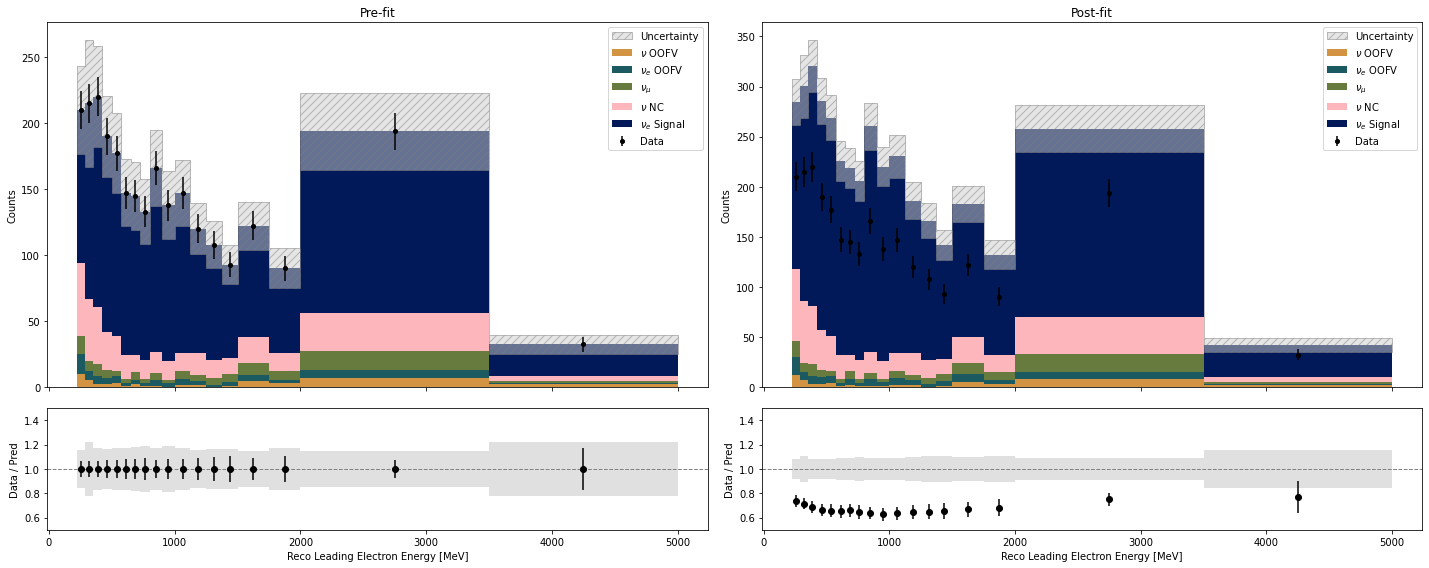

In [13]:
data_pre = np.array(h_mc_pre)
data_post = np.array(h_mc_post)

n_bins = len(x_vals)

labels = [r"$\nu_e$ Signal", r"$\nu_e$ OOFV", r"$\nu_\mu$", r"$\nu$ OOFV", r"$\nu$ NC"]
category_colors = ['#011959', '#1C5A62', '#687B3E', '#D29343', '#FDB7BC']

def draw_stacked_with_band(ax, stack_data, errors, title, data_y=None, data_yerr=None):
    bottom = np.zeros(n_bins)
    totals_per_cat = stack_data.sum(axis=1)
    order = np.argsort(totals_per_cat)  # draw from smallest to largest contribution

    for i in order:
        ax.bar(
            x_vals,
            stack_data[i],
            bottom=bottom,
            width=widths,
            label=labels[i],
            color=category_colors[i],
            align='center'
        )
        bottom += stack_data[i]

    # total prediction and band
    x_edges = [x_vals[0] - widths[0] / 2.0]
    x_edges.extend([x + w / 2.0 for x, w in zip(x_vals, widths)])
    total_pred = np.sum(stack_data, axis=0)
    err = np.asarray(errors, dtype=float)
    lower = np.maximum(0.0, total_pred - err)
    upper = total_pred + err
    ax.fill_between(
        x_edges,
        np.r_[lower, lower[-1]],
        np.r_[upper, upper[-1]],
        step='post',
        facecolor='0.8',
        edgecolor='gray',
        hatch='///',
        alpha=0.5,
        label='Uncertainty'
    )

    # data points
    if data_y is not None:
        y = np.asarray(data_y, dtype=float)
        yerr = np.asarray(data_yerr, dtype=float) if data_yerr is not None else np.zeros_like(y)
        ax.errorbar(
            x_vals,
            y,
            yerr=yerr,
            fmt='o',
            color='black',
            ecolor='black',
            elinewidth=1.5,
            capsize=0,
            markersize=4,
            label='Data',
            zorder=10
        )

    ax.set_ylabel("Counts")
    ax.set_title(title)
    return x_edges, total_pred, err

def draw_ratio(ax, total_pred, err, data_y, data_yerr, x_edges, center=1.0, ypad=(0.5, 1.5)):
    tot = np.asarray(total_pred, dtype=float)
    data_y = np.asarray(data_y, dtype=float)
    data_yerr = np.asarray(data_yerr, dtype=float)

    denom = tot.copy()
    denom[denom == 0.0] = np.nan
    ratio = data_y / denom
    ratio_err = data_yerr / denom

    lower = np.maximum(0.0, (tot - err) / denom)
    upper = (tot + err) / denom

    ax.fill_between(
        x_edges,
        np.r_[lower, lower[-1]],
        np.r_[upper, upper[-1]],
        step='post',
        facecolor='0.8',
        edgecolor='none',
        alpha=0.6,
        zorder=1,
    )
    ax.errorbar(x_vals, ratio, yerr=ratio_err, fmt='o', color='black', zorder=10)
    ax.axhline(center, color='gray', linestyle='--', linewidth=1)
    ax.set_ylim(ypad)
    ax.set_xlabel("Reco Leading Electron Energy [MeV]")
    ax.set_ylabel("Data / Pred")

# Draw main + ratio panels
fig, axes = plt.subplots(2, 2, figsize=(20, 8), gridspec_kw={'height_ratios': [3, 1]}, sharex='col')
ax1_main, ax2_main = axes[0, 0], axes[0, 1]
ax1_ratio, ax2_ratio = axes[1, 0], axes[1, 1]

edges1, tot1, err1 = draw_stacked_with_band(ax1_main, data_pre, preFitErrors, "Pre-fit", data, data_err)
edges2, tot2, err2 = draw_stacked_with_band(ax2_main, data_post, postFitErrors, "Post-fit", data, data_err)

draw_ratio(ax1_ratio, tot1, err1, data, data_err, edges1)
draw_ratio(ax2_ratio, tot2, err2, data, data_err, edges2)

ax1_main.legend(loc='upper right')
ax2_main.legend(loc='upper right')

plt.tight_layout()
plt.show()